# Figure 3 (combined)

Builds the combined Figure 3 panels using the same plot style as Figure 2.


In [8]:
from __future__ import annotations

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure code_repository/notebooks is importable
HERE = Path.cwd().resolve()
if (HERE / 'notebooks').exists():
    SRC_ROOT = HERE / 'notebooks'
elif (HERE / 'code_repository' / 'notebooks').exists():
    SRC_ROOT = HERE / 'code_repository' / 'notebooks'
elif (HERE.parent / 'code_repository' / 'notebooks').exists():
    SRC_ROOT = HERE.parent / 'code_repository' / 'notebooks'
else:
    SRC_ROOT = None
if SRC_ROOT is not None:
    sys.path.insert(0, str(SRC_ROOT))

from analysis.plot_style import apply_style, style_axes, save_figure, set_save_dir
from analysis.model_comparison import rm_tukey_hsd

apply_style()

ROOT = Path.cwd().resolve()
if (ROOT / 'Data').exists():
    PROJECT_ROOT = ROOT
elif (ROOT.parent / 'Data').exists():
    PROJECT_ROOT = ROOT.parent
else:
    PROJECT_ROOT = ROOT

FIGURE_ID = 'figure3'
SAVE_DIR = set_save_dir(PROJECT_ROOT, FIGURE_ID)


In [9]:
import math
import os
import glob
import matplotlib.patches as mpatches


def _rm_anova_pvalue(df: pd.DataFrame, metric: str) -> float:
    try:
        import pingouin as pg
    except Exception:
        return float('nan')
    aov = pg.rm_anova(dv=metric, within='method', subject='cv_cycle', data=df, detailed=True)
    if 'p-gg-corr' in aov.columns:
        return float(aov.loc[aov['Source'] == 'method', 'p-gg-corr'].iloc[0])
    return float(aov.loc[aov['Source'] == 'method', 'p-unc'].iloc[0])


def _bh_adjust(pvals):
    """Benjamini-Hochberg FDR adjustment (returns q-values in original order)."""
    pvals = list(pvals)
    m = len(pvals)
    if m == 0:
        return []
    order = sorted(range(m), key=lambda i: pvals[i])
    ranked = [pvals[i] for i in order]
    q_ranked = []
    for rank, p in enumerate(ranked, start=1):
        q = p * m / rank
        q_ranked.append(1.0 if q > 1.0 else q)
    # Enforce monotonicity from largest to smallest p-value
    prev = 1.0
    for i in range(m - 1, -1, -1):
        prev = min(prev, q_ranked[i])
        q_ranked[i] = prev
    adj = [0.0] * m
    for idx, q in zip(order, q_ranked):
        adj[idx] = q
    return adj

def plot_pr_auc_anova_box(
    ax: plt.Axes,
    df_for_tests: pd.DataFrame,
    metric: str = 'pr_auc',
    alpha: float = 0.05,
    title_prefix: str = 'LLM/Aug methods',
    q_matrix: pd.DataFrame | None = None,
) -> None:
    df = df_for_tests[['cv_cycle', 'method', metric]].dropna().copy()
    k = df['method'].nunique()
    ok = (df.groupby('cv_cycle')['method'].nunique() == k)
    if not ok.all():
        df = df[df['cv_cycle'].isin(ok[ok].index)].copy()

    # Order by mean
    means = df.groupby('method')[metric].mean().sort_values(ascending=False)
    order = means.index.tolist()
    best = order[0]
    best_mean = float(means.iloc[0])

    # Use provided Tukey/BH q-matrix (from figure3_llm_parametric_tests) if available.
    # Fallback: Wilcoxon vs best with BH correction (requires pingouin).
    if q_matrix is None:
        try:
            import pingouin as pg
        except Exception as e:
            raise RuntimeError(
                'Missing q_matrix and pingouin not installed; cannot compute Wilcoxon vs best.'
            ) from e

        wide = df.pivot_table(index='cv_cycle', columns='method', values=metric, aggfunc='mean').dropna(axis=0, how='any')
        pvals = []
        comps = []
        for tag in order[1:]:
            try:
                res = pg.wilcoxon(wide[best], wide[tag])
                p = float(res['p-val'].iloc[0])
            except Exception:
                p = 1.0
            pvals.append(p)
            comps.append(tag)
        qvals = _bh_adjust(pvals)

        import numpy as np
        pmat = pd.DataFrame(np.nan, index=order, columns=order)
        for tag, q in zip(comps, qvals):
            pmat.loc[best, tag] = q
            pmat.loc[tag, best] = q

        def q_vs_best(tag: str) -> float:
            return float(pmat.loc[best, tag])
    else:
        def q_vs_best(tag: str) -> float:
            if (best in q_matrix.index) and (tag in q_matrix.columns):
                return float(q_matrix.loc[best, tag])
            if (best in q_matrix.columns) and (tag in q_matrix.index):
                return float(q_matrix.loc[tag, best])
            return float('nan')

    palette = []
    for tag in order:
        if tag == best:
            palette.append('#1f77b4')
        else:
            q = q_vs_best(tag)
            if (q == q) and (q < alpha) and (means.loc[tag] < best_mean):
                palette.append('#c45c5c')
            else:
                palette.append('#9e9e9e')

    sns.boxplot(
        ax=ax, data=df, x='method', y=metric, order=order,
        whis=1.5, fliersize=2, showfliers=False, palette=palette
    )

    ax.axhline(best_mean, color='#1f77b4', linestyle='--', linewidth=1, alpha=0.9)
    ax.set_xlabel('')
    ax.set_ylabel(metric.replace('_', ' ').upper())
    ax.set_ylim(0, 1.0)
    ax.tick_params(axis='x', rotation=35)
    plt.setp(ax.get_xticklabels(), ha='right', rotation_mode='anchor')

    base_title = f"Impact of LLM/Augmentation methods on model performance"
    ax.set_title(base_title)

    ax.legend(handles=[
        mpatches.Patch(facecolor='#1f77b4', edgecolor='none', label='Best'),
        mpatches.Patch(facecolor='#9e9e9e', edgecolor='none', label=f'Not statistically different vs best (BH q>= {alpha})'),
        mpatches.Patch(facecolor='#c45c5c', edgecolor='none', label=f'Significantly worse (BH q< {alpha})'),
        plt.Line2D([0], [0], color='#1f77b4', lw=1, ls='--', label='Best mean'),
    ], frameon=False, loc='lower left')

    style_axes(ax)
def _load_proteomics_tables(cache_dir: Path) -> tuple[pd.DataFrame, pd.DataFrame]:
    tidy_path = cache_dir / 'tidy_proteomics_cycles.csv'
    stats_path = cache_dir / 'paired_stats_per_model.csv'
    if tidy_path.exists() and stats_path.exists():
        tidy = pd.read_csv(tidy_path)
        paired = pd.read_csv(stats_path)
        if 'p_bonferroni' not in paired.columns and {'Model', 'p'}.issubset(paired.columns):
            alpha = 0.05
            for model_name in paired['Model'].dropna().unique():
                idx = paired['Model'] == model_name
                m = paired.loc[idx, 'p'].notna().sum()
                adj = alpha / max(1, m)
                paired.loc[idx, 'alpha_bonferroni'] = adj
                paired.loc[idx, 'p_bonferroni'] = (paired.loc[idx, 'p'] * m).clip(upper=1.0)
                paired.loc[idx, 'sig_after_bonf'] = paired.loc[idx, 'p_bonferroni'] < alpha
        return tidy, paired

    EXP_TEXT_ROOT = PROJECT_ROOT / 'predictions/Text_vs_No_Text_experiment/multiclass'
    EXP_NOTEXT_ROOT = PROJECT_ROOT / 'predictions/Text_vs_No_Text_experiment/no_text'

    MODELS = [
        ('lightgbm', 'LightGBM'),
        ('pytorch_mlp', 'PyTorch-MLP'),
    ]
    METRICS = [
        ('macro_f1', 'Macro F1', True),
        ('macro_ap_ovr', 'Macro PR AUC (OvR)', True),
        ('macro_roc_ovr', 'Macro ROC AUC (OvR)', True),
    ]

    def _extract_keys_from_filename(path: str):
        base = os.path.basename(path).replace('.pkl', '')
        kv = {}
        for token in base.split('_'):
            if token.startswith('fold'):
                kv['fold_idx'] = int(token.replace('fold', ''))
            if token.startswith('iter'):
                kv['cv_iter'] = int(token.replace('iter', ''))
            if token.startswith('rep'):
                kv['rep_idx'] = int(token.replace('rep', ''))
            if token.startswith('seed'):
                kv['seed'] = int(token.replace('seed', ''))
        return kv

    def _load_pkls(run_dir: str):
        pkls = sorted(glob.glob(os.path.join(run_dir, '*.pkl')))
        if not pkls:
            pkls = sorted(glob.glob(os.path.join(run_dir, '**', '*.pkl'), recursive=True))
        return pkls

    def _is_pairwise_agg(df: pd.DataFrame) -> bool:
        return ('TrueMoA' in df.columns) and ('PredMoA' in df.columns)

    def _is_notext_fold(df: pd.DataFrame) -> bool:
        return ('TrueLbl' in df.columns) and ('PredLbl' in df.columns)

    def _metric_pack():
        return {'macro_f1': np.nan, 'macro_ap_ovr': np.nan, 'macro_roc_ovr': np.nan}

    def _metrics_pairwise_agg(df: pd.DataFrame):
        from sklearn.metrics import f1_score, roc_auc_score, average_precision_score
        out = _metric_pack()
        y_true = df['TrueMoA'].values
        y_pred = df['PredMoA'].values
        present = np.unique(y_true)
        out['macro_f1'] = f1_score(y_true, y_pred, average='macro', labels=present, zero_division=0)
        ovrs_roc, ovrs_ap = [], []
        for c in present:
            if c not in df.columns:
                continue
            y_bin = (y_true == c).astype(int)
            s_c = df[c].to_numpy()
            if y_bin.sum() == 0 or y_bin.sum() == len(y_bin):
                continue
            try:
                ovrs_roc.append(roc_auc_score(y_bin, s_c))
                ovrs_ap.append(average_precision_score(y_bin, s_c))
            except ValueError:
                pass
        out['macro_roc_ovr'] = float(np.mean(ovrs_roc)) if ovrs_roc else np.nan
        out['macro_ap_ovr'] = float(np.mean(ovrs_ap)) if ovrs_ap else np.nan
        return out

    def _metrics_notext(df: pd.DataFrame):
        from sklearn.metrics import f1_score, roc_auc_score, average_precision_score
        out = _metric_pack()
        y_true = df['TrueLbl'].values
        y_pred = df['PredLbl'].values
        present = np.unique(y_true)
        out['macro_f1'] = f1_score(y_true, y_pred, average='macro', labels=present, zero_division=0)
        ovrs_roc, ovrs_ap = [], []
        for c in present:
            key = 'proba_' + str(c)
            if key not in df.columns:
                continue
            y_bin = (y_true == c).astype(int)
            s_c = df[key].to_numpy()
            if y_bin.sum() == 0 or y_bin.sum() == len(y_bin):
                continue
            try:
                ovrs_roc.append(roc_auc_score(y_bin, s_c))
                ovrs_ap.append(average_precision_score(y_bin, s_c))
            except ValueError:
                pass
        out['macro_roc_ovr'] = float(np.mean(ovrs_roc)) if ovrs_roc else np.nan
        out['macro_ap_ovr'] = float(np.mean(ovrs_ap)) if ovrs_ap else np.nan
        return out

    def _load_fold_table(run_dir: str) -> pd.DataFrame:
        rows = []
        for p in _load_pkls(run_dir):
            try:
                df = pd.read_pickle(p)
            except Exception:
                continue
            is_pw = _is_pairwise_agg(df)
            is_nt = _is_notext_fold(df)
            if not (is_pw or is_nt):
                continue
            keys = _extract_keys_from_filename(p)
            for k in ['cv_iter', 'fold_idx', 'rep_idx', 'seed']:
                if (k in df.columns) and (len(df[k]) > 0):
                    keys[k] = df[k].iloc[0]
            metrics = _metrics_pairwise_agg(df) if is_pw else _metrics_notext(df)
            rows.append({**keys, **metrics})
        out = pd.DataFrame(rows)
        return out.dropna(subset=['cv_iter', 'fold_idx', 'rep_idx'])

    def _find_run_dir_text(exp_root: Path, model_key: str) -> str:
        hits = []
        for d, _, files in os.walk(exp_root):
            if any(f.endswith('.pkl') for f in files):
                base = os.path.basename(d)
                if (model_key in base) and base.endswith('Text_Embedding+Proteomics'):
                    hits.append(d)
        if hits:
            return sorted(hits, key=len)[0]
        for d, _, files in os.walk(exp_root):
            if any(f.endswith('.pkl') for f in files):
                base = os.path.basename(d)
                if (model_key in base) and ('Text_Embedding' in base) and ('Proteomics' in base):
                    return d
        raise FileNotFoundError(f'with-text run not found for model={model_key} under {exp_root}')

    def _find_run_dir_notext(exp_root: Path, model_key: str) -> str:
        target = f'no_text__{model_key}_Proteomics'
        for d, _, files in os.walk(exp_root):
            if os.path.basename(d) == target and any(f.endswith('.pkl') for f in files):
                return d
        for d, _, files in os.walk(exp_root):
            base = os.path.basename(d)
            if base.startswith(f'no_text__{model_key}_') and base.endswith('Proteomics') and any(f.endswith('.pkl') for f in files):
                return d
        raise FileNotFoundError(f'no-text run not found for model={model_key} under {exp_root}')

    def _paired_t_and_ci(x, y):
        x = np.asarray(x, dtype=float)
        y = np.asarray(y, dtype=float)
        mask = ~(np.isnan(x) | np.isnan(y))
        x, y = x[mask], y[mask]
        n = len(x)
        if n < 3:
            return dict(n=n, t=np.nan, p=np.nan, mean_diff=np.nan, ci_low=np.nan, ci_high=np.nan, dz=np.nan)
        diffs = x - y
        mean_diff = float(np.mean(diffs))
        sd_diff = float(np.std(diffs, ddof=1))
        from scipy import stats
        t_stat, p_val = stats.ttest_rel(x, y, nan_policy='omit')
        se = sd_diff / math.sqrt(n)
        tcrit = stats.t.ppf(0.975, df=n - 1)
        ci_low, ci_high = mean_diff - tcrit * se, mean_diff + tcrit * se
        dz = mean_diff / sd_diff if sd_diff > 0 else np.inf
        return dict(n=n, t=float(t_stat), p=float(p_val), mean_diff=mean_diff,
                    ci_low=float(ci_low), ci_high=float(ci_high), dz=float(dz))

    tidy_rows = []
    paired_stats_rows = []

    for model_key, model_name in MODELS:
        dir_text = _find_run_dir_text(EXP_TEXT_ROOT, model_key)
        dir_notext = _find_run_dir_notext(EXP_NOTEXT_ROOT, model_key)

        df_text = _load_fold_table(dir_text)
        df_notext = _load_fold_table(dir_notext)

        on = ['cv_iter', 'fold_idx', 'rep_idx']
        merged = pd.merge(
            df_text[on + [m[0] for m in METRICS]].add_prefix('W_'),
            df_notext[on + [m[0] for m in METRICS]].add_prefix('N_'),
            left_on=[f'W_{c}' for c in on],
            right_on=[f'N_{c}' for c in on],
            how='inner'
        )
        merged['cv_cycle'] = merged[['W_cv_iter', 'W_fold_idx', 'W_rep_idx']].astype(int).astype(str).agg('|'.join, axis=1)

        for metric_key, _, _ in METRICS:
            tidy_rows += [{
                'cv_cycle': merged['cv_cycle'].iloc[i],
                'Model': model_name,
                'Method': 'With-Text',
                'metric_key': metric_key,
                'value': merged[f'W_{metric_key}'].iloc[i]
            } for i in range(len(merged))]
            tidy_rows += [{
                'cv_cycle': merged['cv_cycle'].iloc[i],
                'Model': model_name,
                'Method': 'No-Text',
                'metric_key': metric_key,
                'value': merged[f'N_{metric_key}'].iloc[i]
            } for i in range(len(merged))]

            res = _paired_t_and_ci(merged[f'W_{metric_key}'], merged[f'N_{metric_key}'])
            paired_stats_rows.append({
                'Model': model_name,
                'metric_key': metric_key,
                **res,
            })

    tidy = pd.DataFrame(tidy_rows)
    paired_stats = pd.DataFrame(paired_stats_rows)

    alpha = 0.05
    for model_name in paired_stats['Model'].unique():
        m = paired_stats.loc[paired_stats['Model'] == model_name, 'p'].notna().sum()
        adj = alpha / max(1, m)
        idx = paired_stats['Model'] == model_name
        paired_stats.loc[idx, 'alpha_bonferroni'] = adj
        paired_stats.loc[idx, 'p_bonferroni'] = (paired_stats.loc[idx, 'p'] * m).clip(upper=1.0)
        paired_stats.loc[idx, 'sig_after_bonf'] = paired_stats.loc[idx, 'p_bonferroni'] < alpha

    cache_dir.mkdir(parents=True, exist_ok=True)
    tidy.to_csv(tidy_path, index=False)
    paired_stats.to_csv(stats_path, index=False)
    return tidy, paired_stats


def _friedman_overall(df_metric: pd.DataFrame):
    try:
        import pingouin as pg
    except Exception:
        return float('nan')
    df = df_metric[['cv_cycle', 'Model', 'Method', 'value']].dropna().copy()
    df['group'] = df['Model'] + ' | ' + df['Method']
    k = df['group'].nunique()
    ok = (df.groupby('cv_cycle')['group'].nunique() == k)
    df_bal = df[df['cv_cycle'].isin(ok[ok].index)].copy()
    if df_bal.empty:
        return float('nan')
    tab = pg.friedman(data=df_bal.rename(columns={'value': 'score'}),
                      dv='score', within='group', subject='cv_cycle')
    if 'p-unc' in tab.columns:
        return float(tab['p-unc'].iloc[0])
    if 'p' in tab.columns:
        return float(tab['p'].iloc[0])
    return float('nan')


def plot_grouped_box_macro_f1(ax: plt.Axes, tidy: pd.DataFrame, paired_stats: pd.DataFrame) -> None:
    metric_key = 'macro_f1'
    metric_label = 'Macro F1'
    dfp = tidy[tidy['metric_key'] == metric_key].dropna().copy()

    model_order = ['LightGBM', 'PyTorch-MLP']
    method_order = ['No-Text', 'With-Text']
    palette = {'No-Text': '#676E56', 'With-Text': '#9BC53D'}

    sns.boxplot(
        ax=ax, data=dfp, x='Model', y='value', hue='Method',
        order=model_order, hue_order=method_order,
        whis=1.5, fliersize=2, showfliers=False, palette=palette
    )

    handles, labels = ax.get_legend_handles_labels()
    if handles:
        ax.legend(handles=handles[:len(method_order)], labels=labels[:len(method_order)],
                  frameon=False, loc='lower left')

    ax.set_xlabel('')
    ax.set_ylabel(metric_label)
    ax.tick_params(axis='x', rotation=35)
    plt.setp(ax.get_xticklabels(), ha='right', rotation_mode='anchor')
    for label in ax.get_xticklabels():
        label.set_ha('right')
        label.set_rotation_mode('anchor')
    for label in ax.get_xticklabels():
        label.set_ha('right')
        label.set_rotation_mode('anchor')
    ax.grid(True, axis='y', alpha=0.3)
    ax.set_ylim(0.0, 1.0)

    p_friedman = _friedman_overall(dfp)
    if p_friedman == p_friedman:
        ax.set_title("Impact of text embeddings on model performance")
    else:
        ax.set_title(metric_label)

    # Collect box centers for bracket placement
    all_boxes = [p for p in ax.patches if isinstance(p, mpatches.PathPatch)]
    all_boxes = [p for p in all_boxes if p.get_path().vertices[:, 0].ptp() > 0]
    xticks = np.array(ax.get_xticks())
    boxes_by_model = {mdl: [] for mdl in model_order}

    for b in all_boxes:
        verts = b.get_path().vertices
        xmin, xmax = float(np.min(verts[:, 0])), float(np.max(verts[:, 0]))
        x_center = (xmin + xmax) / 2.0
        tick_idx = int(np.argmin(np.abs(xticks - x_center)))
        mdl = model_order[tick_idx]
        boxes_by_model[mdl].append(x_center)

    def whisker_top(group_df):
        q1 = group_df['value'].quantile(0.25)
        q3 = group_df['value'].quantile(0.75)
        iqr = q3 - q1
        return q3 + 1.5 * iqr

    whisker_top_map = {}
    for mdl in model_order:
        for meth in method_order:
            g = dfp[(dfp['Model'] == mdl) & (dfp['Method'] == meth)]
            if not g.empty:
                whisker_top_map[(mdl, meth)] = float(whisker_top(g))

    ymin, ymax = ax.get_ylim()
    y_span = ymax - ymin
    h = 0.05 * y_span
    pad = 0.04 * y_span
    new_ymax = ymax

    for mdl in model_order:
        xs = sorted(boxes_by_model.get(mdl, []))
        if len(xs) < 2:
            continue
        x1, x2 = xs[0], xs[1]
        y1 = whisker_top_map.get((mdl, 'No-Text'), np.nan)
        y2 = whisker_top_map.get((mdl, 'With-Text'), np.nan)
        if np.isnan(y1) or np.isnan(y2):
            continue
        y_bar = max(y1, y2) + pad

        row = paired_stats[(paired_stats['Model'] == mdl) & (paired_stats['metric_key'] == metric_key)]
        if row.empty:
            continue
        p_star = float(row['p_bonferroni'].iloc[0]) if 'p_bonferroni' in row.columns else float(row['p'].iloc[0])
        stars = '****' if p_star < 1e-4 else '***' if p_star < 1e-3 else '**' if p_star < 1e-2 else '*' if p_star < 0.05 else 'ns'

        ax.plot([x1, x1, x2, x2], [y_bar, y_bar + h, y_bar + h, y_bar], lw=1.0, c='k')
        ax.text((x1 + x2) / 2.0, y_bar + h, stars, ha='center', va='bottom', fontsize=9, color='k')
        new_ymax = max(new_ymax, y_bar + h + 0.06 * y_span)

    if new_ymax > ymax:
        ax.set_ylim(ymin, new_ymax)

    style_axes(ax)


/tmp/ipykernel_4744/3708256981.py:110: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_4744/3310407188.py:26: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


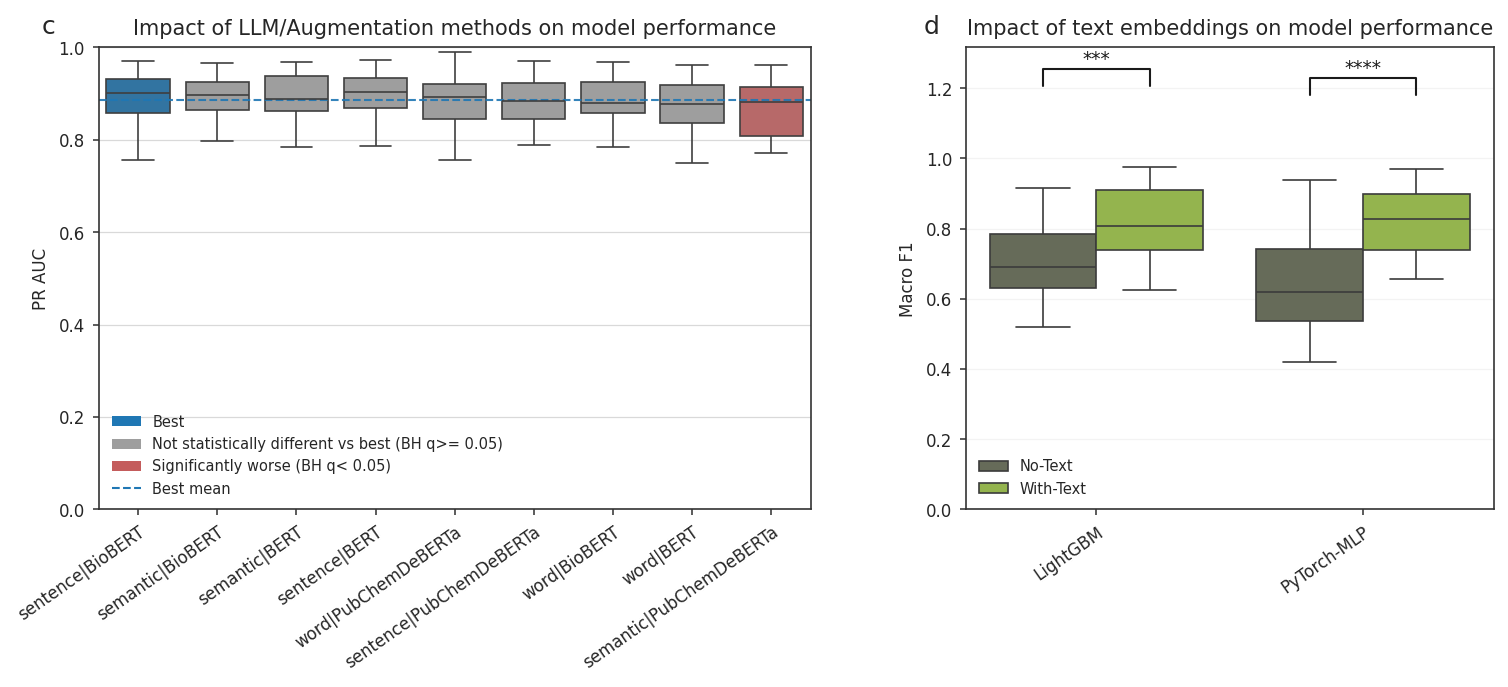

In [10]:
# ---- Load data ----
ANOVA_INPUT = PROJECT_ROOT / 'analysis_exports/LLM_augmentation_experiment/rm_anova_input.csv'
if not ANOVA_INPUT.exists():
    raise FileNotFoundError(f'Missing rm_anova_input.csv at {ANOVA_INPUT}')

df_for_tests = pd.read_csv(ANOVA_INPUT)
TKEY_QMAT = PROJECT_ROOT / 'analysis_exports/LLM_augmentation_experiment/tukey_pr_auc_pvals_matrix.csv'
tukey_qmat = pd.read_csv(TKEY_QMAT, index_col=0) if TKEY_QMAT.exists() else None

proteomics_cache = PROJECT_ROOT / 'analysis_exports/text_vs_notext_proteomics_grouped_stars'
tidy, paired_stats = _load_proteomics_tables(proteomics_cache)

# ---- Build combined figure ----
fig = plt.figure(figsize=(12, 4.0))
gs = fig.add_gridspec(1, 2, width_ratios=[1.35, 1.0], wspace=0.25)

ax_left = fig.add_subplot(gs[0, 0])
ax_right = fig.add_subplot(gs[0, 1])

plot_pr_auc_anova_box(ax_left, df_for_tests, metric='pr_auc', alpha=0.05, title_prefix='LLM/Aug methods', q_matrix=tukey_qmat)
plot_grouped_box_macro_f1(ax_right, tidy, paired_stats)

ax_left.text(-0.08, 1.03, 'c', transform=ax_left.transAxes, fontsize=12, fontweight='normal')
ax_right.text(-0.08, 1.03, 'd', transform=ax_right.transAxes, fontsize=12, fontweight='normal')

fig.tight_layout()
save_figure(fig, 'figure3_combined')
plt.show()
